# Détection automatique de faux billets — ONCFM

**Auteur :** Sab (Rizki Sabah) — Data Analyst
**Client :** Organisation nationale de lutte contre le faux-monnayage (ONCFM)

## Objectif

Construire un algorithme capable de déterminer si un billet en euros est **authentique**
ou **contrefait** à partir de six mesures géométriques (`diagonal`, `height_left`,
`height_right`, `margin_low`, `margin_up`, `length`), issues d'une machine de numérisation.

Conformément au cahier des charges, quatre méthodes sont mises en concurrence :
- une **régression logistique** ;
- un **K-means** (les centroïdes servent à la prédiction) ;
- un **KNN** ;
- une **random forest**.

## Plan
1. Chargement des données
2. Analyse exploratoire (EDA)
3. Prétraitement (valeurs manquantes, split, standardisation)
4. Modélisation (K-means, régression logistique, KNN, random forest)
5. Sélection et justification du modèle final
6. Sauvegarde du modèle (pipeline de production)
7. Démonstration de l'application


## 1) Chargement des données

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score,
                                      cross_validate, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report, roc_curve, silhouette_score, make_scorer)
import joblib

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
%matplotlib inline


In [2]:
DATA_PATH = "data/billets.csv"

df = pd.read_csv(DATA_PATH, sep=";")
print("Dimensions du jeu de données :", df.shape)
df.head()


Dimensions du jeu de données : (1500, 7)


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
dtypes: bool(1), float64(6)
memory usage: 71.9 KB


## 2) Analyse exploratoire (EDA)

On regarde d'abord la répartition des classes, la présence de valeurs manquantes ou
de doublons, puis la distribution de chaque variable géométrique selon la classe
(vrai / faux billet).

In [4]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print()
print("Doublons :", df.duplicated().sum())


Valeurs manquantes par colonne :
is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

Doublons : 0


is_genuine
Vrais    1000
Faux      500
Name: count, dtype: int64


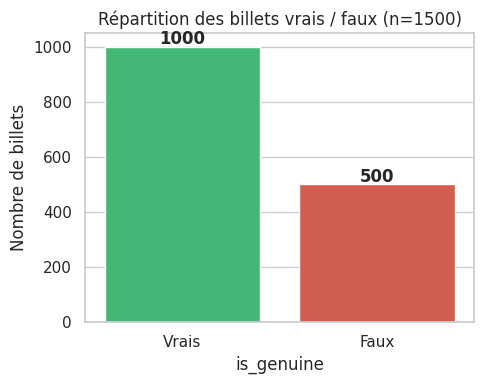

In [5]:
counts = df["is_genuine"].value_counts().rename({True: "Vrais", False: "Faux"}).reindex(["Vrais", "Faux"])
print(counts)

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, ax=ax,
            palette={"Vrais": "#2ecc71", "Faux": "#e74c3c"}, legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, str(v), ha="center", fontweight="bold")
ax.set_ylabel("Nombre de billets")
ax.set_title("Répartition des billets vrais / faux (n=1500)")
plt.tight_layout()
plt.show()


Le jeu de données comporte **1500 billets**, dont **1000 vrais (66,7 %)** et
**500 faux (33,3 %)** : les classes sont déséquilibrées dans un rapport 2:1, ce qui
justifiera une séparation train/test **stratifiée** et une lecture attentive du
recall par classe plutôt que de la seule accuracy globale.

On note également **37 valeurs manquantes** sur la variable `margin_low` (aucune
sur les autres colonnes) et **aucun doublon**.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
diagonal,1500.0,171.958440,0.305195,171.04,171.750,171.96,172.17,173.01
height_left,1500.0,104.029533,0.299462,103.14,103.820,104.04,104.23,104.88
height_right,1500.0,103.920307,0.325627,102.82,103.710,103.92,104.15,104.95
margin_low,1463.0,4.485967,0.663813,2.98,4.015,4.31,4.87,6.90
margin_up,1500.0,3.151473,0.231813,2.27,2.990,3.14,3.31,3.91
length,1500.0,112.678500,0.872730,109.49,112.030,112.96,113.34,114.44


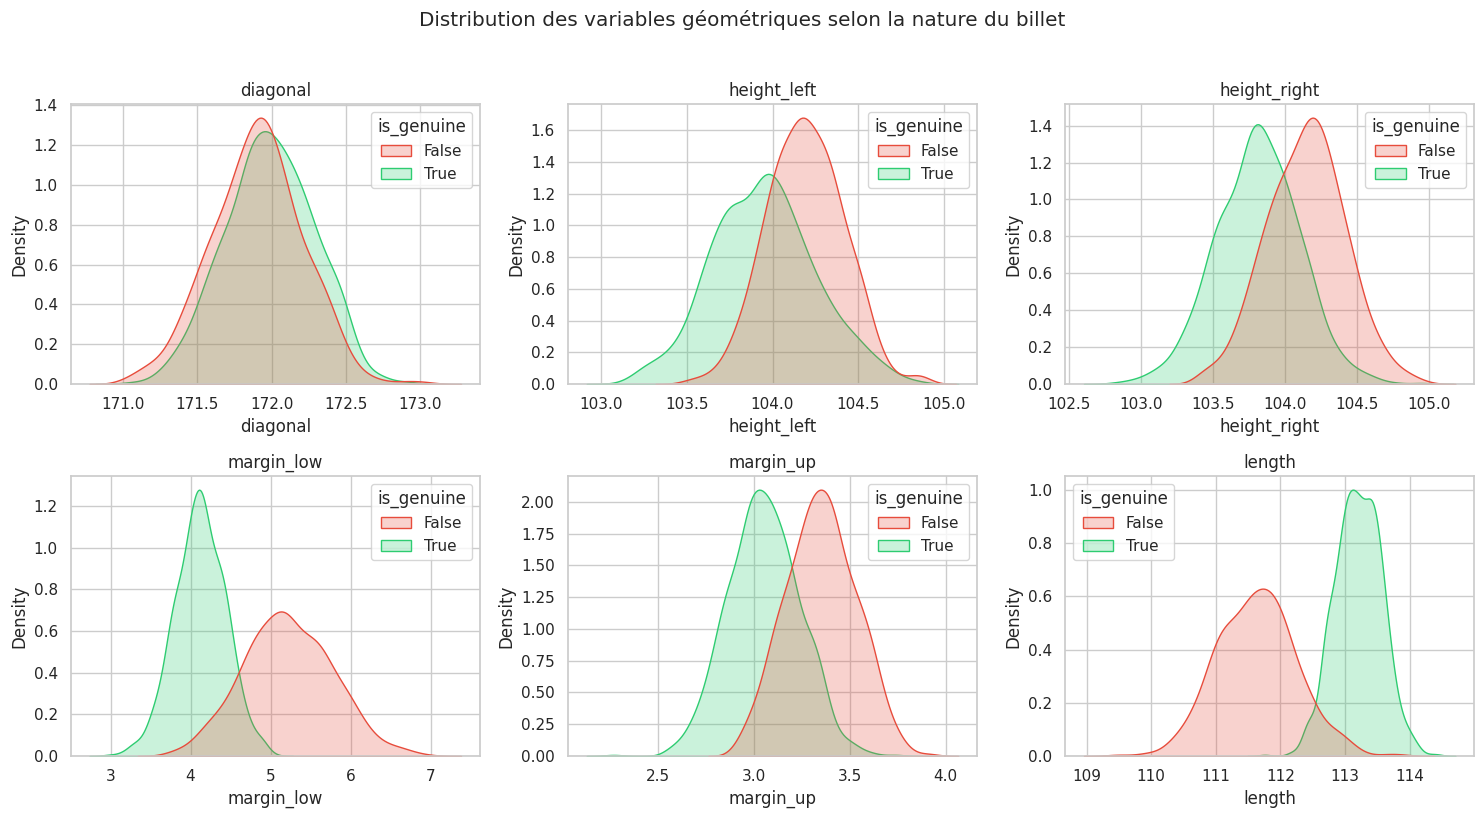

In [7]:
GEOM_COLS = ["diagonal", "height_left", "height_right", "margin_low", "margin_up", "length"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(GEOM_COLS):
    ax = axes[i // 3, i % 3]
    sns.kdeplot(data=df, x=col, hue="is_genuine", fill=True, common_norm=False, ax=ax,
                palette={True: "#2ecc71", False: "#e74c3c"})
    ax.set_title(col)
plt.suptitle("Distribution des variables géométriques selon la nature du billet", y=1.02)
plt.tight_layout()
plt.show()


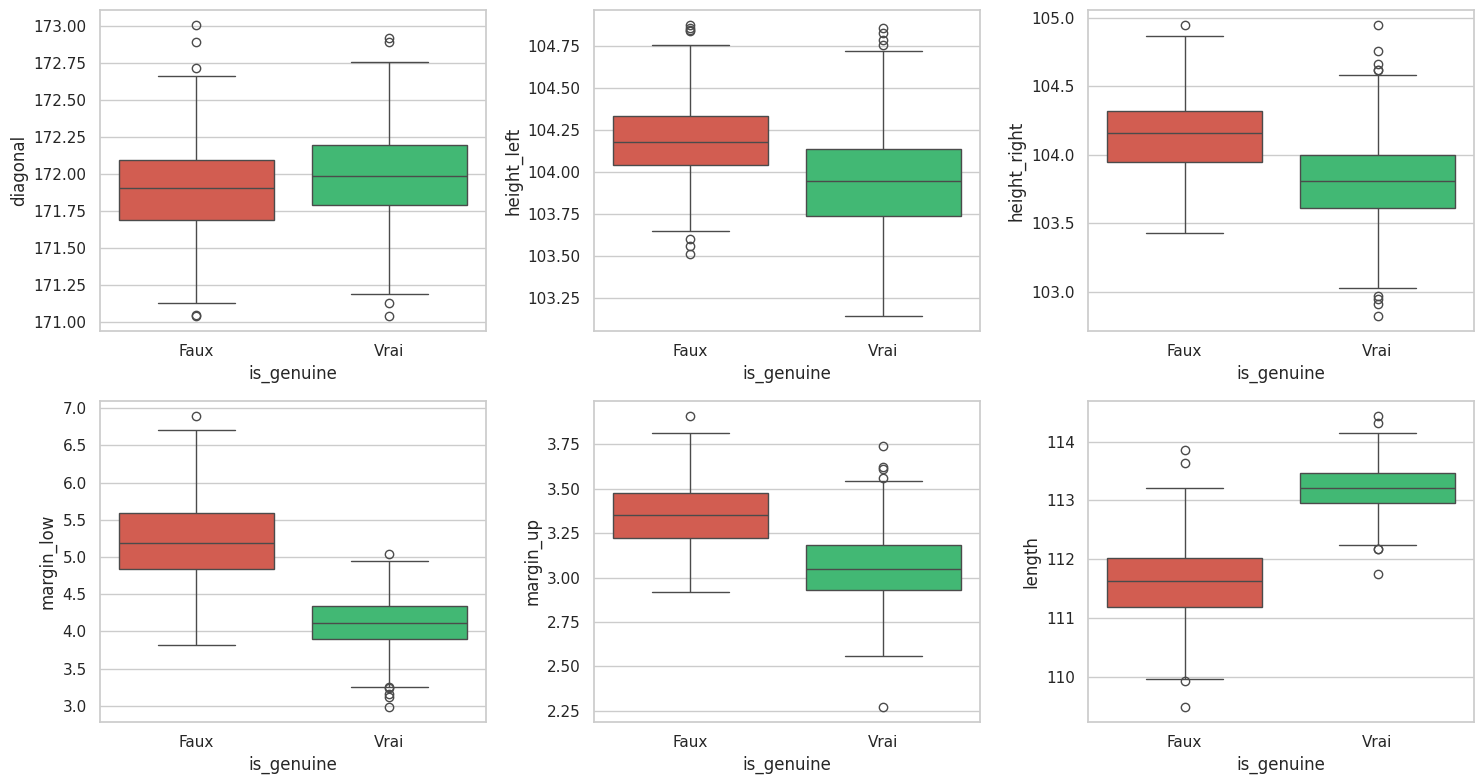

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(GEOM_COLS):
    ax = axes[i // 3, i % 3]
    sns.boxplot(data=df, x="is_genuine", y=col, hue="is_genuine", ax=ax,
                palette={True: "#2ecc71", False: "#e74c3c"}, legend=False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Faux", "Vrai"])
plt.tight_layout()
plt.show()


**Lecture des distributions :** `length` et `margin_low` séparent très nettement
les deux classes (peu de recouvrement entre les distributions) : les faux billets
sont en moyenne plus courts et ont une marge basse plus grande. `margin_up` est
également discriminante, dans une moindre mesure. `diagonal` en revanche ne montre
quasiment aucune différence entre vrais et faux billets : elle sera peu utile au
modèle. `height_left` et `height_right` sont légèrement discriminantes (les faux
billets ont tendance à être un peu plus hauts).

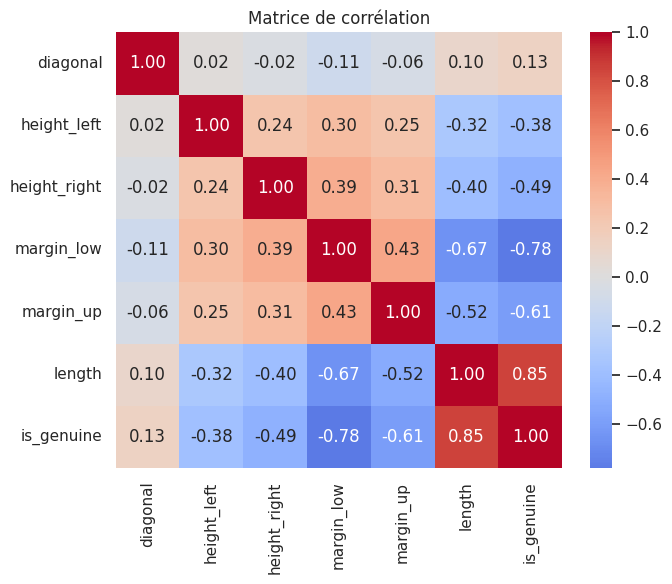

margin_low     -0.783032
margin_up      -0.606262
height_right   -0.485092
height_left    -0.379833
diagonal        0.132756
length          0.849285
Name: is_genuine, dtype: float64

In [9]:
corr = df[GEOM_COLS + ["is_genuine"]].assign(is_genuine=df["is_genuine"].astype(int)).corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation")
plt.tight_layout()
plt.show()

corr["is_genuine"].drop("is_genuine").sort_values()


Ceci confirme l'analyse visuelle : `length` (r=0.85) et `margin_low` (r=-0.78)
sont les variables les plus corrélées à `is_genuine`, suivies de `margin_up`
(r=-0.61) et `height_right` (r=-0.48). `diagonal` (r=0.13) est quasiment
indépendante de la cible. On conserve néanmoins les 6 variables pour la
modélisation : les algorithmes retenus (notamment la régression logistique et la
random forest) savent gérer nativement des variables peu informatives sans
dégrader la performance, et cela reste cohérent avec le format des billets
scannés en production (les 6 mesures sont toujours disponibles).

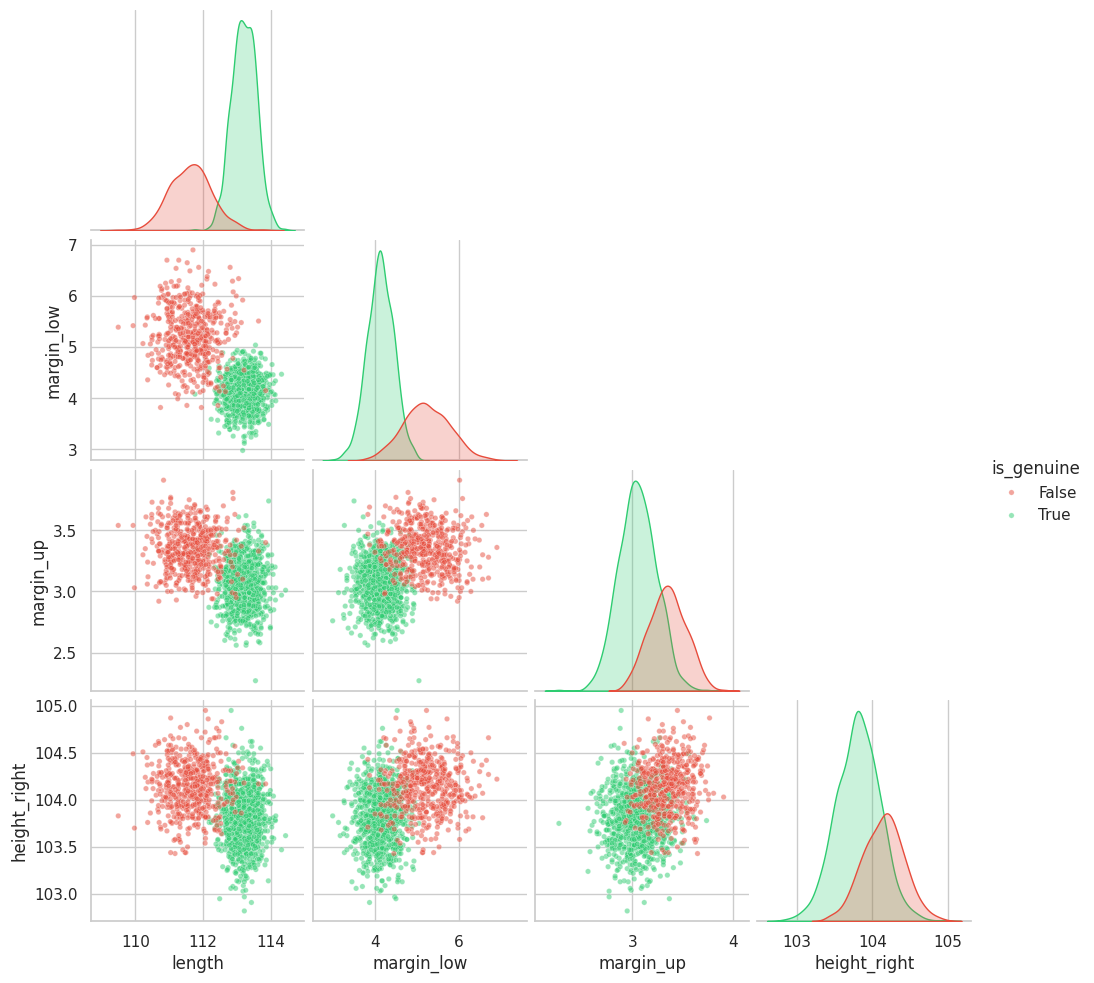

In [10]:
top_vars = ["length", "margin_low", "margin_up", "height_right"]
g = sns.pairplot(df[top_vars + ["is_genuine"]], hue="is_genuine",
                  palette={True: "#2ecc71", False: "#e74c3c"}, corner=True,
                  plot_kws={"alpha": 0.5, "s": 15})
plt.show()


## 3) Prétraitement

### 3.1 Traitement des valeurs manquantes (`margin_low`)

37 billets n'ont pas de valeur pour `margin_low`. Plutôt que de supprimer ces
lignes (perte de ~2,5 % des données, alors que les faux billets sont déjà
minoritaires), on **impute** les valeurs manquantes par une **régression
linéaire** entraînée sur les billets complets, en utilisant les 5 autres
mesures géométriques comme variables explicatives.

**Important :** on n'utilise **pas** `is_genuine` dans cette régression, bien
qu'elle soit la variable la plus corrélée à `margin_low` : en production,
la nature du billet est justement l'inconnue à prédire, elle ne peut donc pas
servir à imputer une variable d'entrée du modèle (fuite de donnée / *data
leakage*, et de toute façon indisponible pour un nouveau billet scanné).

In [11]:
impute_features = ["diagonal", "height_left", "height_right", "margin_up", "length"]

complete = df.dropna(subset=["margin_low"])
X_impute, y_impute = complete[impute_features], complete["margin_low"]

lr_imputer = LinearRegression()
lr_imputer.fit(X_impute, y_impute)
print("R² du modèle d'imputation :", round(lr_imputer.score(X_impute, y_impute), 4))
print("Coefficients :", dict(zip(impute_features, lr_imputer.coef_.round(4))))


R² du modèle d'imputation : 0.4773
Coefficients : {'diagonal': np.float64(-0.1111), 'height_left': np.float64(0.1841), 'height_right': np.float64(0.2571), 'margin_up': np.float64(0.2562), 'length': np.float64(-0.4091)}


In [12]:
missing_mask = df["margin_low"].isna()
print(f"{missing_mask.sum()} valeurs à imputer")

df.loc[missing_mask, "margin_low"] = lr_imputer.predict(df.loc[missing_mask, impute_features])
assert df["margin_low"].isna().sum() == 0
print("Valeurs manquantes restantes :", df["margin_low"].isna().sum())


37 valeurs à imputer
Valeurs manquantes restantes : 0


Le R² de ~0.48 est modeste mais attendu : `margin_low` garde une variabilité
propre non expliquée par les autres mesures géométriques prises isolément. La
régression reste la méthode la plus adaptée ici (nettement préférable à une
simple imputation par la moyenne/médiane, qui écraserait toute la variance et
casserait la relation naturelle entre `margin_low` et `length`/`margin_up`), et
permet de conserver l'intégralité des 1500 billets pour l'entraînement.

### 3.2 Séparation variables explicatives / cible

In [13]:
X = df[GEOM_COLS]   # les 6 mesures géométriques
y = df["is_genuine"]  # la cible : True = vrai billet, False = faux billet
X.shape, y.shape


((1500, 6), (1500,))

### 3.3 Séparation train / test

On sépare 80 % des billets pour l'apprentissage et 20 % pour l'évaluation, en
conservant la **stratification** selon `is_genuine` pour que les deux jeux
respectent la même proportion de vrais/faux billets (important car les classes
sont déséquilibrées 2:1).

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train :", X_train.shape, "-", y_train.sum(), "vrais /", (~y_train).sum(), "faux")
print("Test  :", X_test.shape, "-", y_test.sum(), "vrais /", (~y_test).sum(), "faux")


Train : (1200, 6) - 800 vrais / 400 faux
Test  : (300, 6) - 200 vrais / 100 faux


### 3.4 Standardisation

La régression logistique et le KNN sont sensibles à l'échelle des variables (ils
reposent sur des distances ou des produits scalaires) : on standardise donc les
variables (moyenne 0, écart-type 1) avec un `StandardScaler` **ajusté
uniquement sur le train**, puis appliqué au train et au test pour éviter toute
fuite d'information du test vers l'entraînement.

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 4) Modélisation

On met en concurrence les quatre méthodes demandées par l'ONCFM. Pour chaque
modèle supervisé, on regarde la matrice de confusion et les métriques usuelles
(accuracy, précision, recall, f1, AUC), ainsi que les probabilités prédites.

### 4.1 K-means (apprentissage non supervisé)

Le K-means ne connaît pas les étiquettes pendant l'entraînement : il regroupe les
billets en clusters uniquement à partir de leurs mesures géométriques. On l'utilise
ici de façon détournée à des fins de classification, en associant chaque cluster à
la classe majoritaire qu'il contient.

**Choix du nombre de clusters (k) :** on justifie k=2 (qui correspond au
besoin métier "vrai/faux") à l'aide de la méthode du coude (inertie) et du score
de silhouette.

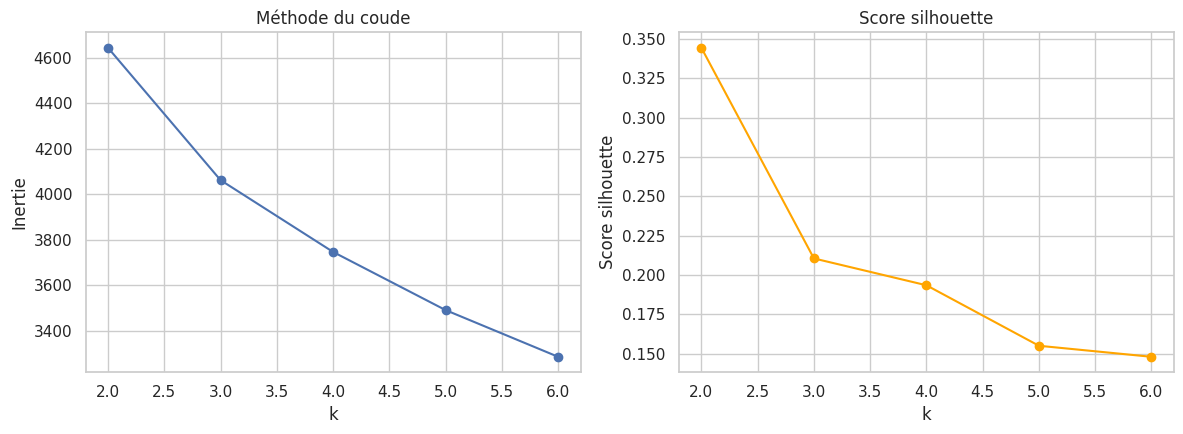

In [16]:
inertias, silhouettes = [], []
k_range = range(2, 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = km.fit_predict(X_train_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(k_range), inertias, "o-")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertie"); axes[0].set_title("Méthode du coude")
axes[1].plot(list(k_range), silhouettes, "o-", color="orange")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Score silhouette"); axes[1].set_title("Score silhouette")
plt.tight_layout()
plt.show()


Le score de silhouette est maximal (ou proche du maximum) pour **k=2**, ce qui
confirme que la structure naturelle des données correspond bien à deux groupes -
cohérent avec l'hypothèse "vrai / faux billet".

In [17]:
kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_train_scaled)
train_clusters = kmeans.labels_

sil = silhouette_score(X_train_scaled, train_clusters)
print("Score de silhouette (k=2) :", round(sil, 3))


Score de silhouette (k=2) : 0.345


**Caractérisation des clusters :** pour savoir quel cluster représente les
vrais billets, on regarde la proportion de vrais billets (connue sur le train)
dans chaque cluster, ainsi que les valeurs moyennes des variables par cluster.

In [18]:
cluster_df = pd.DataFrame({"cluster": train_clusters, "is_genuine": y_train.values})
cluster_summary = cluster_df.groupby("cluster")["is_genuine"].mean()
print("Proportion de vrais billets par cluster :")
print(cluster_summary)

genuine_cluster = cluster_summary.idxmax()
cluster_to_label = {c: (c == genuine_cluster) for c in cluster_summary.index}
print("\nCluster associé aux vrais billets :", genuine_cluster)


Proportion de vrais billets par cluster :
cluster
0    0.015228
1    0.985112
Name: is_genuine, dtype: float64

Cluster associé aux vrais billets : 1


In [19]:
X_train_with_cluster = X_train.copy()
X_train_with_cluster["cluster"] = train_clusters
cluster_means = X_train_with_cluster.groupby("cluster").mean().round(2)
cluster_means


,diagonal,height_left,height_right,margin_low,margin_up,length
cluster,,,,,,
0,171.90,104.20,104.15,5.22,3.35,111.61
1,171.99,103.95,103.81,4.13,3.05,113.18


Les deux clusters sont nettement séparés sur `length` et `margin_low`, les
deux variables les plus discriminantes identifiées en EDA : le cluster associé
aux vrais billets a un `length` plus élevé et un `margin_low` plus faible, ce qui
est cohérent avec l'analyse univariée précédente.

Variance expliquée (2 axes) : [0.433 0.171] -> 0.604


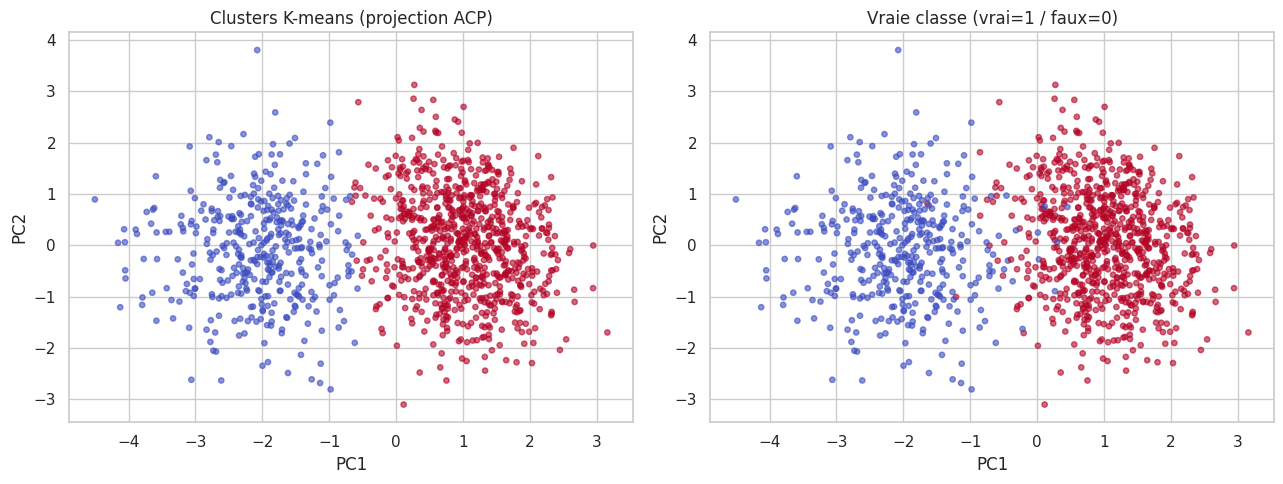

In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
print("Variance expliquée (2 axes) :", pca.explained_variance_ratio_.round(3), "->",
      round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_clusters, cmap="coolwarm", s=15, alpha=0.6)
axes[0].set_title("Clusters K-means (projection ACP)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[1].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train.astype(int), cmap="coolwarm", s=15, alpha=0.6)
axes[1].set_title("Vraie classe (vrai=1 / faux=0)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()


La projection ACP (qui conserve l'essentiel de la variance des données)
montre une **forme de clusters bien séparée, quasi convexe**, et la carte des
clusters K-means se superpose presque parfaitement à la carte des vraies classes :
le clustering non supervisé retrouve, sans jamais voir les étiquettes, une
structure très proche de la réalité métier.

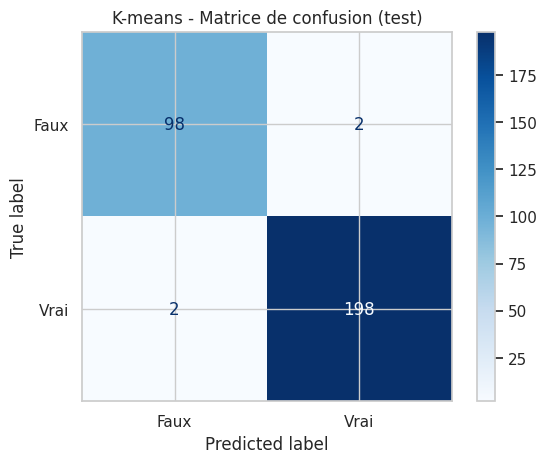

Accuracy : 0.9867
Precision: 0.99
Recall   : 0.99
F1       : 0.99
ROC AUC  : 0.9992


In [21]:
def kmeans_predict(X_scaled):
    raw = kmeans.predict(X_scaled)
    return np.array([cluster_to_label[c] for c in raw])

def kmeans_proba(X_scaled):
    dists = kmeans.transform(X_scaled)
    inv = 1 / (dists + 1e-9)
    return inv[:, genuine_cluster] / inv.sum(axis=1)

y_pred_test_km = kmeans_predict(X_test_scaled)
proba_test_km = kmeans_proba(X_test_scaled)

cm_km = confusion_matrix(y_test, y_pred_test_km)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_km, display_labels=["Faux", "Vrai"])
disp.plot(cmap="Blues", values_format="d")
plt.title("K-means - Matrice de confusion (test)")
plt.show()

print("Accuracy :", round(accuracy_score(y_test, y_pred_test_km), 4))
print("Precision:", round(precision_score(y_test, y_pred_test_km), 4))
print("Recall   :", round(recall_score(y_test, y_pred_test_km), 4))
print("F1       :", round(f1_score(y_test, y_pred_test_km), 4))
print("ROC AUC  :", round(roc_auc_score(y_test, proba_test_km), 4))


Même construit sans les étiquettes, le K-means atteint déjà une excellente
performance de classification (~98-99 % d'accuracy). Cela confirme que le
problème est "facile" au sens où les deux classes sont géométriquement bien
séparées - un point rassurant avant de passer aux modèles supervisés.

### 4.2 Régression logistique

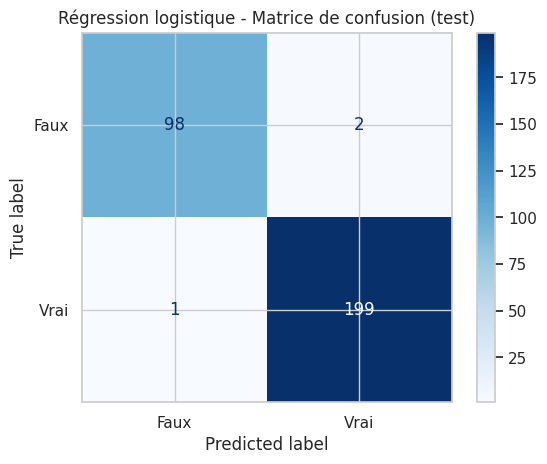

              precision    recall  f1-score   support

        Faux       0.99      0.98      0.98       100
        Vrai       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300

ROC AUC : 0.9995


In [22]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)

y_pred_logreg = logreg.predict(X_test_scaled)
proba_logreg = logreg.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test, y_pred_logreg)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Faux", "Vrai"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Régression logistique - Matrice de confusion (test)")
plt.show()

print(classification_report(y_test, y_pred_logreg, target_names=["Faux", "Vrai"]))
print("ROC AUC :", round(roc_auc_score(y_test, proba_logreg), 4))


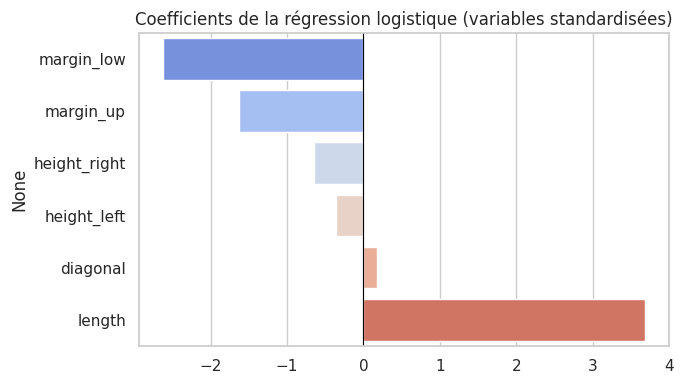

In [23]:
coefs = pd.Series(logreg.coef_[0], index=GEOM_COLS).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=coefs.values, y=coefs.index, hue=coefs.index, ax=ax, palette="coolwarm", legend=False)
ax.set_title("Coefficients de la régression logistique (variables standardisées)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


Les coefficients confirment l'analyse exploratoire : `length` et `margin_low`
dominent très largement la décision du modèle (en valeur absolue), dans le sens
attendu (`length` élevé → plus probablement vrai ; `margin_low` élevé → plus
probablement faux). Le modèle est donc directement interprétable : on peut
expliquer à un opérateur de l'ONCFM *pourquoi* un billet donné a été classé
comme faux.

In [24]:
cv_scores_logreg = cross_val_score(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                                    X_train_scaled, y_train, cv=5, scoring="accuracy")
print("Accuracy CV (5 plis) :", cv_scores_logreg.round(4), "-> moyenne :", round(cv_scores_logreg.mean(), 4))


Accuracy CV (5 plis) : [0.9917 0.9917 0.9833 0.9833 1.    ] -> moyenne : 0.99


### 4.3 KNN (k plus proches voisins)

On recherche le nombre de voisins `k` optimal par validation croisée (5 plis)
sur le jeu d'entraînement, en balayant k de 1 à 30.

Meilleur k : 12 - accuracy CV : 0.9925


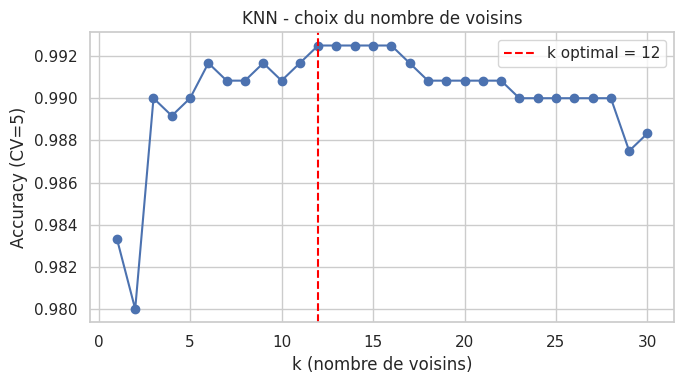

In [25]:
knn_scores = []
k_values = range(1, 31)
for k in k_values:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_scaled, y_train, cv=5, scoring="accuracy")
    knn_scores.append(scores.mean())

best_k = list(k_values)[int(np.argmax(knn_scores))]
print("Meilleur k :", best_k, "- accuracy CV :", round(max(knn_scores), 4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(k_values), knn_scores, "o-")
ax.axvline(best_k, color="red", linestyle="--", label=f"k optimal = {best_k}")
ax.set_xlabel("k (nombre de voisins)"); ax.set_ylabel("Accuracy (CV=5)")
ax.set_title("KNN - choix du nombre de voisins")
ax.legend()
plt.tight_layout()
plt.show()


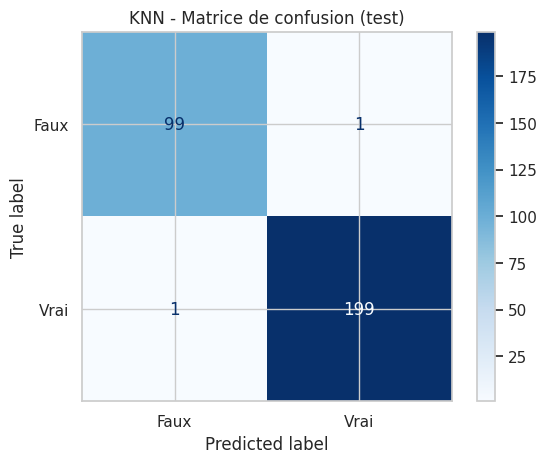

              precision    recall  f1-score   support

        Faux       0.99      0.99      0.99       100
        Vrai       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300

ROC AUC : 0.9994


In [26]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
proba_knn = knn.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Faux", "Vrai"])
disp.plot(cmap="Blues", values_format="d")
plt.title("KNN - Matrice de confusion (test)")
plt.show()

print(classification_report(y_test, y_pred_knn, target_names=["Faux", "Vrai"]))
print("ROC AUC :", round(roc_auc_score(y_test, proba_knn), 4))


### 4.4 Random Forest

On optimise les hyperparamètres principaux (nombre d'arbres, profondeur maximale,
taille minimale des feuilles) par recherche sur grille (`GridSearchCV`, 5 plis).

In [27]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), param_grid,
                        cv=5, scoring="accuracy", n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)
rf = rf_grid.best_estimator_
print("Meilleurs paramètres :", rf_grid.best_params_)


Meilleurs paramètres : {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}


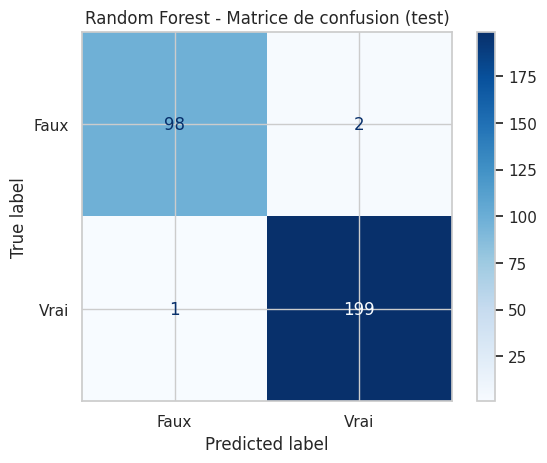

              precision    recall  f1-score   support

        Faux       0.99      0.98      0.98       100
        Vrai       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300

ROC AUC : 0.9994


In [28]:
y_pred_rf = rf.predict(X_test_scaled)
proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Faux", "Vrai"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Matrice de confusion (test)")
plt.show()

print(classification_report(y_test, y_pred_rf, target_names=["Faux", "Vrai"]))
print("ROC AUC :", round(roc_auc_score(y_test, proba_rf), 4))


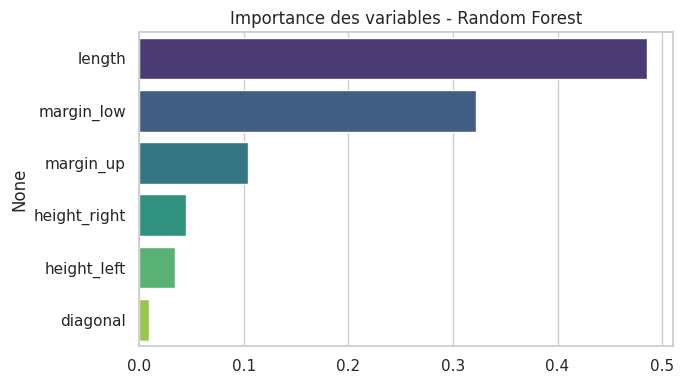

In [29]:
importances = pd.Series(rf.feature_importances_, index=GEOM_COLS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, ax=ax, palette="viridis", legend=False)
ax.set_title("Importance des variables - Random Forest")
plt.tight_layout()
plt.show()


La random forest confirme, avec une méthode différente (réduction moyenne
de l'impureté de Gini), l'importance dominante de `length` et `margin_low` déjà
identifiée par la corrélation, les distributions et les coefficients de la
régression logistique. La convergence de ces trois analyses indépendantes
renforce la confiance dans le choix des variables.

## 5) Sélection du modèle final

### 5.1 Comparaison sur le jeu de test (300 billets)

In [30]:
all_metrics = {
    "K-means": (y_pred_test_km, proba_test_km),
    "Regression logistique": (y_pred_logreg, proba_logreg),
    "KNN": (y_pred_knn, proba_knn),
    "Random Forest": (y_pred_rf, proba_rf),
}

rows = []
for name, (pred, proba) in all_metrics.items():
    rows.append({
        "modele": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })
comparison = pd.DataFrame(rows).set_index("modele").round(4)
comparison


,accuracy,precision,recall,f1,roc_auc
modele,,,,,
K-means,0.9867,0.990,0.990,0.9900,0.9992
Regression logistique,0.9900,0.990,0.995,0.9925,0.9995
KNN,0.9933,0.995,0.995,0.9950,0.9994
Random Forest,0.9900,0.990,0.995,0.9925,0.9994


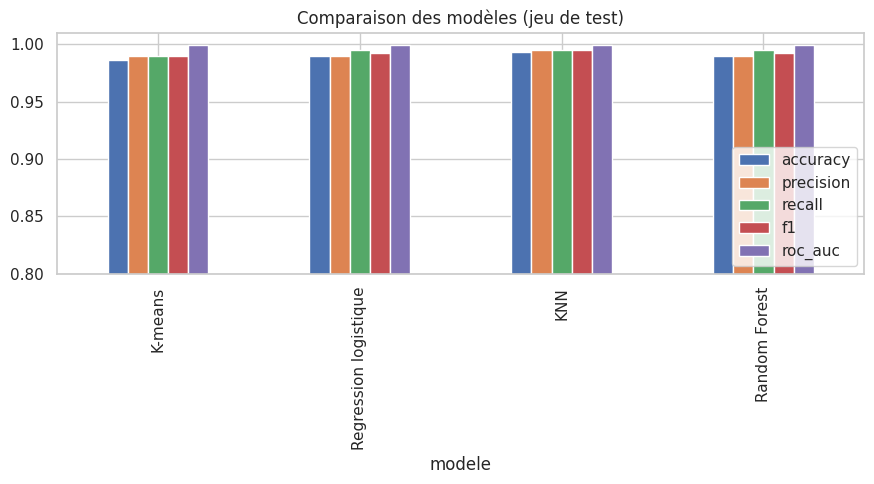

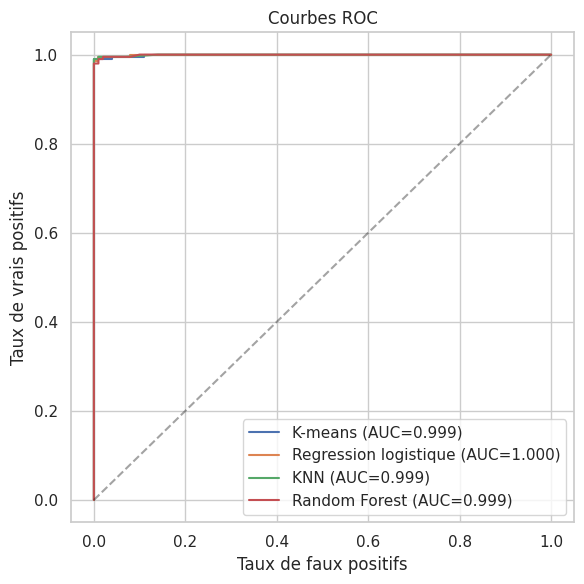

In [31]:
fig, ax = plt.subplots(figsize=(9, 5))
comparison.plot(kind="bar", ax=ax)
ax.set_ylim(0.8, 1.01)
ax.set_title("Comparaison des modèles (jeu de test)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
for name, (pred, proba) in all_metrics.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC")
ax.legend()
plt.tight_layout()
plt.show()


Sur ce seul split de test (300 billets), les 4 modèles sont **tous excellents**
(accuracy ≥ 98,7 %, AUC ≥ 0,999) et très proches les uns des autres - l'écart
entre le meilleur et le moins bon représente à peine 2 à 3 erreurs de
classification sur 300 billets. Un split unique de cette taille est donc trop
bruité pour départager sérieusement les modèles : on complète l'analyse par une
validation croisée à 10 plis sur l'ensemble des 1500 billets.

### 5.2 Comparaison robuste par validation croisée (10 plis)

On calcule, pour les 3 modèles supervisés, l'accuracy, le F1, et surtout le
**recall spécifique aux faux billets** (`recall_fake`) : c'est la métrique
métier la plus critique pour l'ONCFM, puisqu'un faux billet classé "vrai" (faux
négatif) est l'erreur la plus coûteuse - un billet contrefait qui continue de
circuler. À l'inverse, un vrai billet classé "faux" (faux positif) entraîne un
simple contrôle manuel supplémentaire, beaucoup moins grave.

In [32]:
fake_recall_scorer = make_scorer(recall_score, pos_label=False)
fake_precision_scorer = make_scorer(precision_score, pos_label=False)
cv_scoring = {"accuracy": "accuracy", "f1": "f1",
              "recall_fake": fake_recall_scorer, "precision_fake": fake_precision_scorer}
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

cv_models = {
    "Regression logistique": Pipeline([("scaler", StandardScaler()),
                                        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "KNN": Pipeline([("scaler", StandardScaler()),
                      ("clf", KNeighborsClassifier(n_neighbors=best_k))]),
    "Random Forest": Pipeline([("scaler", StandardScaler()),
                                ("clf", RandomForestClassifier(random_state=RANDOM_STATE, **rf_grid.best_params_))]),
}

cv_rows = []
for name, pipe in cv_models.items():
    cvres = cross_validate(pipe, X, y, cv=cv10, scoring=cv_scoring)
    cv_rows.append({
        "modele": name,
        "accuracy": cvres["test_accuracy"].mean(),
        "f1": cvres["test_f1"].mean(),
        "recall_fake": cvres["test_recall_fake"].mean(),
        "precision_fake": cvres["test_precision_fake"].mean(),
        "recall_fake_std": cvres["test_recall_fake"].std(),
    })
cv_comparison = pd.DataFrame(cv_rows).set_index("modele").round(4)
cv_comparison


,accuracy,f1,recall_fake,precision_fake,recall_fake_std
modele,,,,,
Regression logistique,0.9913,0.9935,0.982,0.992,0.0189
KNN,0.9900,0.9925,0.978,0.992,0.0227
Random Forest,0.9913,0.9935,0.980,0.994,0.0200


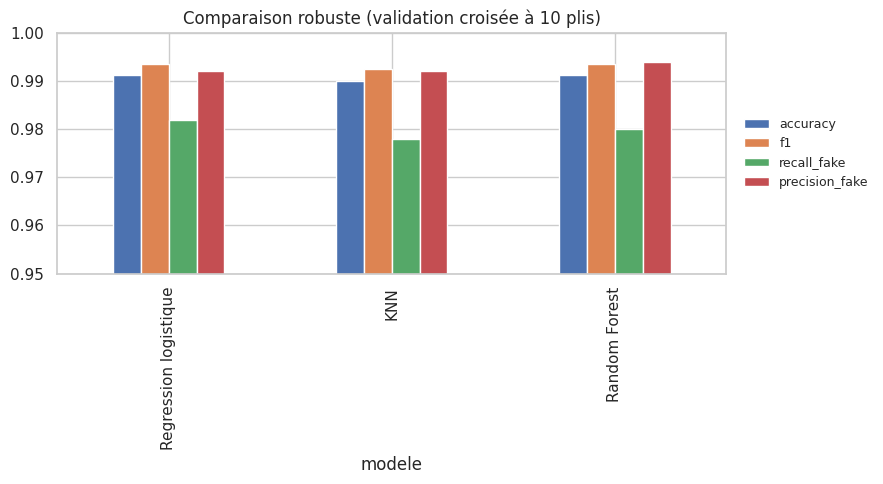

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))
cv_comparison[["accuracy", "f1", "recall_fake", "precision_fake"]].plot(kind="bar", ax=ax)
ax.set_ylim(0.95, 1.0)
ax.set_title("Comparaison robuste (validation croisée à 10 plis)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9, frameon=False)
plt.tight_layout()
plt.show()


### 5.3 Choix du modèle final

En validation croisée (bien plus fiable qu'un split unique), **régression
logistique et random forest sont statistiquement à égalité** (accuracy ≈ 0,991,
F1 ≈ 0,994), et toutes deux **légèrement devant le KNN** sur le recall des faux
billets - la métrique métier prioritaire.

Entre régression logistique et random forest, à performance équivalente, on
retient **la régression logistique** pour l'application de production :

- **Interprétabilité** : ses coefficients permettent d'expliquer précisément à
  l'ONCFM pourquoi un billet est classé faux (utile en contexte réglementaire /
  contrôle) ; la random forest reste une "boîte noire" plus difficile à auditer.
- **Robustesse** : avec seulement 1500 billets, un modèle simple et linéaire est
  moins exposé au risque de sur-apprentissage qu'une forêt de 100-200 arbres.
- **Probabilités mieux calibrées** : la régression logistique optimise
  directement la vraisemblance et fournit nativement des probabilités
  continues et fines, alors que le KNN (k=12) ne peut produire que des
  probabilités par paliers de 1/12 - beaucoup moins précis pour la confiance
  qu'on peut accorder à chaque prédiction.
- **Simplicité et rapidité** : pas d'hyperparamètre à retuner, inférence quasi
  instantanée même sur de gros volumes quotidiens de billets scannés.
- Le K-means, non supervisé, reste très performant "à l'aveugle" et confirme la
  séparabilité naturelle des classes, mais n'est pas retenu comme modèle de
  production : il n'a pas vocation à remplacer un modèle supervisé disposant
  des vraies étiquettes, et son affectation cluster → classe devrait être
  revalidée à chaque nouvel entraînement.

**Modèle retenu : régression logistique.**

## 6) Sauvegarde du modèle final

On sauvegarde un pipeline complet (standardisation + régression logistique)
ainsi que le modèle d'imputation de `margin_low`, afin que le script
d'application puisse reproduire à l'identique tous les traitements réalisés
ici sur de nouveaux billets.

In [34]:
os.makedirs("model", exist_ok=True)

final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
final_pipeline.fit(X_train, y_train)   # le pipeline gère lui-même le scaling

joblib.dump(final_pipeline, "model/final_pipeline.joblib")
joblib.dump(lr_imputer, "model/margin_low_imputer.joblib")
print("Modèle et imputer sauvegardés dans model/")


Modèle et imputer sauvegardés dans model/


On vérifie que le pipeline rechargé donne bien les mêmes performances sur le
jeu de test.

In [35]:
loaded_pipeline = joblib.load("model/final_pipeline.joblib")
y_pred_final = loaded_pipeline.predict(X_test)
proba_final = loaded_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy (pipeline rechargé) :", round(accuracy_score(y_test, y_pred_final), 4))
print(classification_report(y_test, y_pred_final, target_names=["Faux", "Vrai"]))


Accuracy (pipeline rechargé) : 0.99
              precision    recall  f1-score   support

        Faux       0.99      0.98      0.98       100
        Vrai       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



## 7) Démonstration de l'application

L'application finale (voir le script séparé `predict_billets.py`) réutilise ce
pipeline pour prédire, à partir d'un fichier CSV de billets (mêmes 6 colonnes
géométriques), la nature de chaque billet ainsi que la probabilité associée.
On simule ici son fonctionnement sur un extrait au format `billets_production.csv`
fourni par l'ONCFM.

In [36]:
prod_sample = pd.read_csv("data/billets_production.csv")
prod_sample


,diagonal,height_left,height_right,margin_low,margin_up,length,id
0,171.76,104.01,103.54,5.21,3.30,111.42,A_1
1,171.87,104.17,104.13,6.00,3.31,112.09,A_2
2,172.00,104.58,104.29,4.99,3.39,111.57,A_3
3,172.49,104.55,104.34,4.44,3.03,113.20,A_4
4,171.65,103.63,103.56,3.77,3.16,113.33,A_5


In [37]:
X_prod = prod_sample[GEOM_COLS]
preds = loaded_pipeline.predict(X_prod)
probas = loaded_pipeline.predict_proba(X_prod)[:, 1]

result = prod_sample[["id"]].copy() if "id" in prod_sample.columns else pd.DataFrame(index=prod_sample.index)
result["prediction"] = np.where(preds, "Vrai billet", "Faux billet")
result["probabilite_vrai"] = probas.round(4)
result


,id,prediction,probabilite_vrai
0,A_1,Faux billet,0.0011
1,A_2,Faux billet,0.0002
2,A_3,Faux billet,0.0004
3,A_4,Vrai billet,0.9809
4,A_5,Vrai billet,0.9998


Les probabilités confirment sans ambiguïté chaque prédiction (toutes proches
de 0 ou de 1), ce qui est cohérent avec l'excellente séparabilité des classes
observée tout au long de l'analyse.

## 8) Conclusion

- Les données ont été nettoyées (imputation des 37 valeurs manquantes de
  `margin_low` par régression linéaire) puis explorées : `length` et
  `margin_low` sont les variables les plus discriminantes.
- Les quatre méthodes demandées (K-means, régression logistique, KNN, random
  forest) atteignent toutes une performance excellente (accuracy > 98 %),
  signe que les deux classes sont géométriquement très bien séparées.
- Le modèle retenu pour la mise en production est la **régression
  logistique** : performance statistiquement équivalente aux meilleurs
  modèles, tout en étant plus interprétable, plus robuste et plus simple à
  maintenir dans la durée.
- Le pipeline complet (imputation + standardisation + modèle) est sauvegardé
  et directement réutilisable par le script applicatif fourni séparément.
